In [10]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import random

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

random.seed(0)

#### Coding the tricks

- Simple trick
- Absolute trick
- Square trick

In [2]:
def simple_trick(base_price, price_per_room, num_rooms, price):
    small_random_1 = random.random() * 0.1
    small_random_2 = random.random() * 0.1

    predicted_price = base_price + price_per_room * num_rooms
    if (price > predicted_price) and (num_rooms > 0):
        price_per_room += small_random_1    # add η1 to slope
        base_price += small_random_2    # add η2 to y-intercept
    if price > predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    if price < predicted_price and num_rooms > 0:
        price_per_room -= small_random_1
        base_price -= small_random_2
    if price < predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    return price_per_room, base_price

In [3]:
def square_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    # Calculates the prediction
    predicted_price = (price_per_room * num_rooms) + base_price 
    base_price += learning_rate * (price - predicted_price) # Translates the line
    price_per_room += learning_rate * num_rooms * (price - predicted_price) #  Rotates the line
    # predicted_price = (price_per_room * num_rooms) + base_price

    return price_per_room, base_price

In [4]:
def absolute_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + (price_per_room * num_rooms)
    if (price > predicted_price):
        price_per_room += learning_rate * num_rooms
        base_price += learning_rate
    else:
        price_per_room -= learning_rate * num_rooms
        base_price -= learning_rate
        
    return price_per_room, base_price

___
#### Defining the dataset

In [5]:
features = np.array([1, 2, 3, 5, 6, 7])
labels = np.array([155, 197, 244, 356, 407, 448])

print(features)
print(labels)

[1 2 3 5 6 7]
[155 197 244 356 407 448]


#### Plotting the dataset

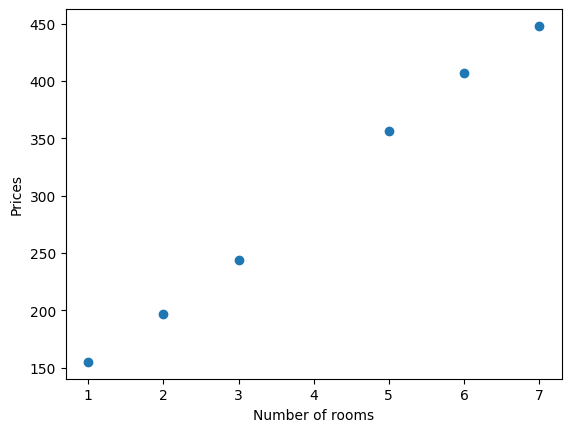

In [6]:
def draw_line(slope, y_intercept, color="grey", linewidth=0.7, starting=0, ending=8):
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, (slope * x) + y_intercept, linestyle="-", color=color, linewidth=linewidth)

def plot_points(features, labels):
    X = features
    y = labels
    plt.scatter(X, y)
    plt.xlabel("Number of rooms")
    plt.ylabel("Prices")

plot_points(features, labels)

____
### Running the linear regression algorithm

The linear regression algorithm consists of:
- Starting with random weights
- Iterating the square (or simple, or absolute) trick many times.

Note that we have used the Python random package to generate random numbers for our initial values (slope and y-intercept) and for selecting our points inside the loop:

Each iteration of the loop is called an epoch, and we set this number at the beginning of
our algorithm. 
The next step is to run this algorithm to build a model that fits our dataset.

Price per room:  51.05347808556453
Base price:  99.0970202799414


(np.float64(51.05347808556453), np.float64(99.0970202799414))

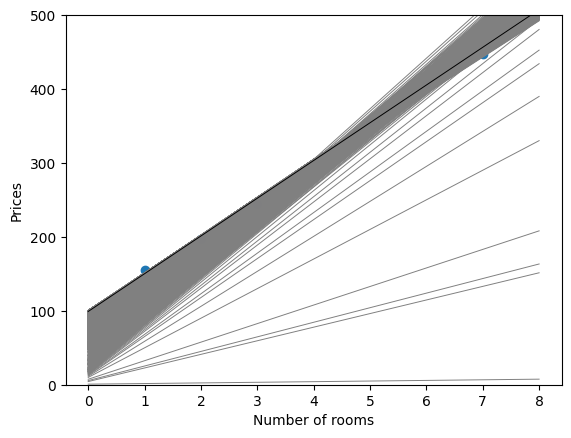

In [7]:
def linear_regression(features, labels, learning_rate=0.01, epochs=10000):
    # Generates (pseudo) rdm values for the slope and the y-intercept
    price_per_room = random.random()    
    base_price = random.random()
    # Repeats the update step many times
    for epoch in range(epochs):
        # Uncomment any of the following lines to plot different epochs
        #if epoch == 1:
        #if epoch <= 10:
        #if epoch <= 50:
        #if epoch > 50:
        if True:
            draw_line(price_per_room, base_price, starting=0, ending=8)
        i = random.randint(0, len(features)-1) # Picks a random point on our dataset
        num_rooms = features[i]
        price = labels[i]

        # Applies the square trick to move the line closer to our point
        price_per_room, base_price = square_trick(base_price, 
                                                  price_per_room, 
                                                  num_rooms, 
                                                  price, 
                                                  learning_rate=learning_rate)

    draw_line(price_per_room, base_price, "black", starting=0, ending=8)
    plot_points(features, labels)
    print("Price per room: ", price_per_room)
    print("Base price: ", base_price)

    return price_per_room, base_price

# This line is for the x-axis to appear in the figure
plt.ylim(0, 500)

linear_regression(features, labels, learning_rate=0.01, epochs=10000)  

#### Root Mean Square Error (RMSE) function

RMSE measures the average magnitude of prediction errors.

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

- $n$: number of data points
- $y_i$: actual value
- $\hat{y}_i$: predicted value

**Interpretation:** Subtract predictions from actual values, square the errors, calculate their mean, and take the square root.

In NumPy, `np.dot(differences, differences)` calculates the sum of squared errors.

In [8]:
# The root mean square error function
def rmse(labels, predictions):
    n = len(labels)
    differences = np.subtract(labels, predictions)
    
    return np.sqrt(1.0/n * (np.dot(differences, differences)))

Taking the Root Mean Square Errors of the predictions:

Price per room:  50.80146197445225
Base price:  100.0144049078708


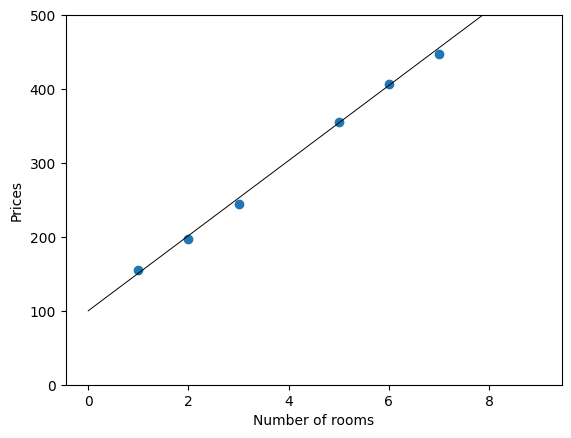

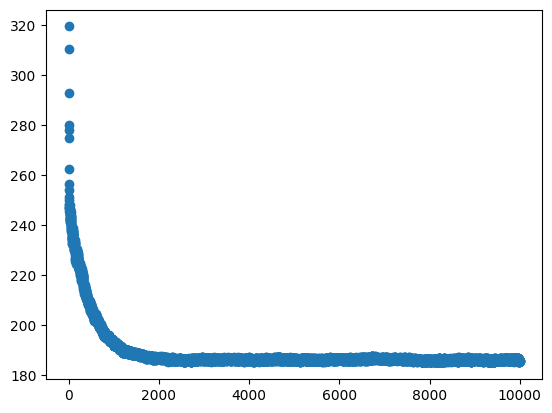

(np.float64(50.80146197445225), np.float64(100.0144049078708))

In [9]:
def linear_regression(features, labels, learning_rate=0.01, epochs=10000):
    # Generates (pseudo) rdm values for the slope and the y-intercept
    price_per_room = random.random()    
    base_price = random.random()
    errors = []

    # Repeats the update step many times
    for epoch in range(epochs):
        predictions = (price_per_room * features[0]) + base_price
        errors.append(rmse(labels, predictions))

        i = random.randint(0, len(features)-1) # Picks a random point on our dataset
        num_rooms = features[i]
        price = labels[i]

        # Applies the square trick to move the line closer to our point
        price_per_room, base_price = square_trick(base_price, 
                                                  price_per_room, 
                                                  num_rooms, 
                                                  price, 
                                                  learning_rate=learning_rate)

    draw_line(price_per_room, base_price, "black", starting=0, ending=9)
    plot_points(features, labels)
    print("Price per room: ", price_per_room)
    print("Base price: ", base_price)
    plt.show()

    plt.scatter(range(len(errors)), errors)
    plt.show()

    return price_per_room, base_price

# This line is for the x-axis to appear in the figure
plt.ylim(0, 500)

linear_regression(features, labels, learning_rate=0.01, epochs=10000) 

_____
#### Real-life application: Using scikit-learn to predict housing prices in India

This dataset has 2,518 rows (one per house) and 40 columns (39 features and
one label). As you can imagine, we won’t code the algorithm by hand.
Instead, we use scikit-learn, a popular and useful package in which many
machine learning algorithms are implemented. For storing and manipulating
tables, we’ll use another popular package called Pandas. 

We start by downloading the data into a Pandas DataFrame, using the following
command:

In [12]:
url = "https://raw.githubusercontent.com/luisguiserrano/manning/master/Chapter_03_Linear_Regression/Hyderabad.csv"
data = pd.read_csv(url)
data.head()

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,1,1,0,1,0,0,1,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,1,1,0,1,0,1,1,0,1,1,1,1,0,1,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,5739000,1295,Alwal,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0
